# Step 2 — Pilot 标签与数据质量

用数学 grader 写入 `correct`，检查完成率、正确率、正负样本平衡和长度关系。

**Go/No-Go：** 正确率最好落在 30%–70%；至少要求两类都有、少数类 ≥10%。若不满足，应调整题目难度，而不是直接扩采。

In [12]:
from pathlib import Path
import os
import sys
#config["grader_model_id"] = "Qwen/Qwen2.5-Math-7B-Instruct"
candidates = [Path.cwd(), *Path.cwd().parents, Path("/content/ZIP-RC-Colab"), Path("/content/ZIP-RC")]
REPO = next(
    (path for path in candidates if (path / "notebooks" / "ziprc_notebook_utils.py").exists()),
    None,
)
if REPO is None:
    raise FileNotFoundError("找不到 ZIP-RC 仓库；请从仓库根目录或 notebooks/ 运行。")

colab_python = Path("/content/mamba/envs/zip/bin/python")
if colab_python.exists():
    os.environ["ZIPRC_PYTHON"] = str(colab_python)

sys.path.insert(0, str(REPO / "notebooks"))
from ziprc_notebook_utils import *

CONFIG = load_config(REPO)
print("Repository:", REPO)
print("Experiment:", CONFIG["experiment_name"])


Repository: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab
Experiment: qwen3_0.6b_ziprc_small_validation


In [15]:
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

In [16]:
RUN_STAGE = True

pilot_path = REPO / CONFIG["paths"]["pilot"]
grader_metrics = REPO / "artifacts/metrics/pilot_grader.json"
if RUN_STAGE:
    run_repo(
        REPO,
        "python3", "src/evaluate_and_label_rollouts.py",
        "--data", pilot_path,
        "--model", CONFIG["grader_model_id"],
        "--tensor-parallel-size", 1,
        "--gpu-memory-utilization", CONFIG["gpu_memory_utilization"],
        "--max-model-len", CONFIG["grader_max_model_len"],
        "--max-num-seqs", CONFIG["max_num_seqs"],
        "--dtype", CONFIG["dtype"],
        "--output-json", grader_metrics,
        "--show-examples",
    )

Progress checkpoint: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/progress/evaluate_and_label_rollouts__pilot_grader.json
Running: /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/.venv/bin/python src/evaluate_and_label_rollouts.py --data /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/data/pilot_rollouts.parquet --model Qwen/Qwen2.5-Math-1.5B-Instruct --tensor-parallel-size 1 --gpu-memory-utilization 0.85 --max-model-len 4096 --max-num-seqs 2 --dtype bfloat16 --output-json /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/metrics/pilot_grader.json --show-examples
INFO 09-30 13:44:42 [__init__.py:239] Automatically detected platform cuda.
INFO 09-30 13:44:53 [config.py:717] This model supports multiple tasks: {'classify', 'generate', 'reward', 'score', 'embed'}. Defaulting to 'generate'.
INFO 09-30 13:44:53 [llm_engine.py:240] Initializing a V0 LLM engine (v0.8.5.post1) with config: model='Qwen/Qwen2.5-Math-1.5B-Instruct',

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.59it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.59it/s]



INFO 09-30 13:45:38 [loader.py:458] Loading weights took 0.35 seconds
INFO 09-30 13:45:39 [model_runner.py:1140] Model loading took 2.8798 GiB and 43.319500 seconds
INFO 09-30 13:45:40 [worker.py:287] Memory profiling takes 0.72 seconds
INFO 09-30 13:45:40 [worker.py:287] the current vLLM instance can use total_gpu_memory (23.52GiB) x gpu_memory_utilization (0.85) = 19.99GiB
INFO 09-30 13:45:40 [worker.py:287] model weights take 2.88GiB; non_torch_memory takes 0.08GiB; PyTorch activation peak memory takes 0.26GiB; the rest of the memory reserved for KV Cache is 16.77GiB.
INFO 09-30 13:45:40 [executor_base.py:112] # cuda blocks: 39258, # CPU blocks: 9362
INFO 09-30 13:45:40 [executor_base.py:117] Maximum concurrency for 4096 tokens per request: 153.35x
INFO 09-30 13:45:45 [model_runner.py:1450] Capturing cudagraphs for decoding. This may lead to unexpected consequences if the model is not static. To run the model in eager mode, set 'enforce_eager=True' or use '--enforce-eager' in the CL

Capturing CUDA graph shapes: 100%|██████████| 2/2 [00:00<00:00,  2.22it/s]


INFO 09-30 13:45:46 [model_runner.py:1592] Graph capturing finished in 1 secs, took 0.05 GiB
INFO 09-30 13:45:46 [llm_engine.py:437] init engine (profile, create kv cache, warmup model) took 6.85 seconds


Processed prompts: 100%|██████████| 370/370 [00:10<00:00, 33.91it/s, est. speed input: 34434.49 toks/s, output: 108.60 toks/s]


Wrote evaluation examples to /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/data/pilot_rollouts_examples.txt
Finished responses: 370/400 (92.50%)
Average total tokens:      1596
Average n-latency:        938.33
Pass@n Accuracy:         92.50%
Skipping expected_reward-based metrics (no 'expected_reward' column).
Best-of-n Accuracy (shortest-response, reasoning-preferred): 83.00%
Precision (best of n shortest response): 84.26%
Evaluation time: 11.48s

✓ Saved evaluation results to /ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/metrics/pilot_grader.json


/ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/src/evaluate_and_label_rollouts.py:1052: RuntimeWarning: 11 grader outputs were invalid. Legacy contains-Yes fallback was used. Examples: row 72: 'The final answer is \\boxed{Yes.}', row 90: '1. **Understanding the problem:**', row 91: 'The final answer is \\boxed{No.}', row 132: 'You are a helpful assistant. You are given a task to determine if the final', row 133: '1265'
  warnings.warn(
[rank0]:[W930 13:46:00.045437777 ProcessGroupNCCL.cpp:1496] Warning: WARNING: destroy_process_group() was not called before program exit, which can leak resources. For more info, please see https://pytorch.org/docs/stable/distributed.html#shutdown (function operator())


Command elapsed time: 1.4 minutes


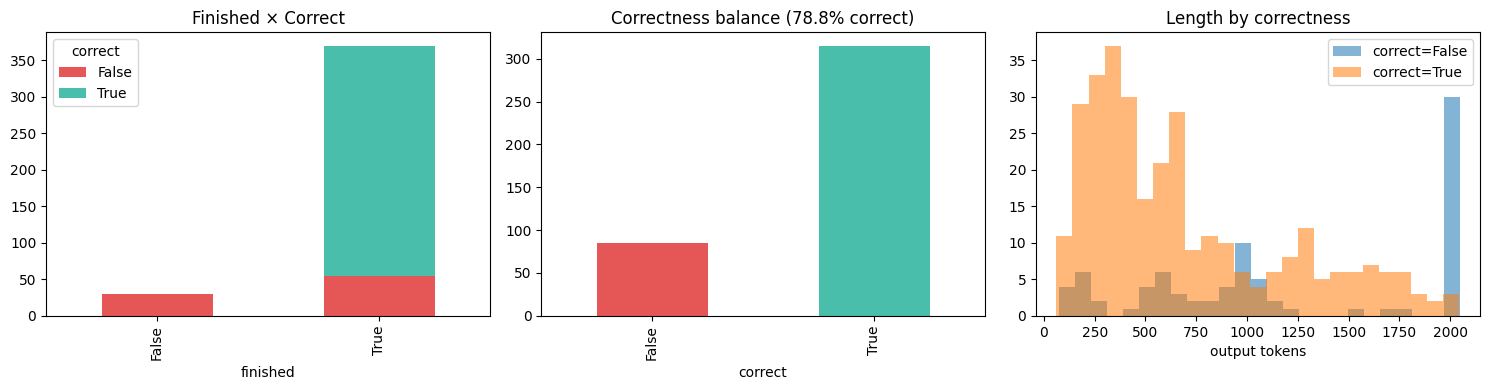

,count,mean,std,min,25%,50%,75%,max
correct,,,,,,,,
False,85.0,1200.1,706.4,73.0,617.0,1002.0,2048.0,2048.0
True,315.0,689.7,490.9,61.0,311.5,547.0,954.0,2046.0


,类型,检查项,状态,说明
0,operational,Correct 标签完整,✅ 通过,null=0
1,scientific,正负样本同时存在,✅ 通过,"{True: 315, False: 85}"
2,scientific,少数类 ≥10%,✅ 通过,minority=21.2%
3,scientific,理想正确率 30%–70%,⚠️ 检查,accuracy=78.8%


PosixPath('/ssddata/hzhuaq/Developer/github.com/wtree101/ZIP-RC-Colab/artifacts/stage_reports/02_pilot_quality.json')

In [17]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

df = pd.read_parquet(pilot_path)
missing = require_columns(df, ["finished", "correct", "length"])
if missing:
    raise ValueError(f"缺少列: {missing}")
accuracy = float(df["correct"].mean())
class_share = df["correct"].value_counts(normalize=True)
minority_share = float(class_share.min()) if len(class_share) == 2 else 0.0

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
pd.crosstab(df["finished"], df["correct"]).plot.bar(stacked=True, ax=axes[0], color=["#e45756", "#49beaa"])
axes[0].set_title("Finished × Correct")
df["correct"].value_counts().sort_index().plot.bar(ax=axes[1], color=["#e45756", "#49beaa"])
axes[1].set_title(f"Correctness balance ({accuracy:.1%} correct)")
for label, group in df.groupby("correct"):
    axes[2].hist(group["length"], bins=25, alpha=.55, label=f"correct={label}")
axes[2].set(title="Length by correctness", xlabel="output tokens")
axes[2].legend()
plt.tight_layout()
plt.show()

display(df.groupby("correct")["length"].describe().round(1))
checks = [
    gate("Correct 标签完整", not missing and df["correct"].notna().all(), f"null={int(df['correct'].isna().sum())}"),
    gate("正负样本同时存在", df["correct"].nunique() == 2, str(df["correct"].value_counts().to_dict()), kind="scientific"),
    gate("少数类 ≥10%", minority_share >= 0.10, f"minority={minority_share:.1%}", kind="scientific"),
    gate("理想正确率 30%–70%", 0.30 <= accuracy <= 0.70, f"accuracy={accuracy:.1%}", kind="scientific"),
]
display(gate_frame(checks))
save_stage_report(REPO, "02_pilot_quality", checks, {"accuracy": accuracy, "minority_share": minority_share, "finished_rate": float(df['finished'].mean())})

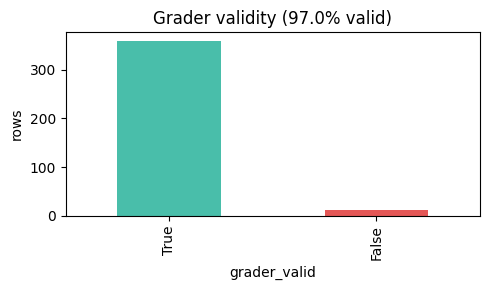

,类型,检查项,状态,说明
0,operational,Finished rows 的 grader 输出全部有效,⚠️ 检查,valid=359/370


/tmp/ipykernel_3743739/4191751351.py:37: RuntimeWarning: 存在无效 grader 输出；批处理已跑完，但这些行的 correct=False 只是回退值。
  warnings.warn(


In [18]:
import warnings

finished_labels = df.loc[df["finished"]]
if "grader_valid" in finished_labels.columns:
    grader_valid = finished_labels["grader_valid"].fillna(False).astype(bool)
else:
    grader_valid = pd.Series(False, index=finished_labels.index)
grader_valid_rate = float(grader_valid.mean()) if len(grader_valid) else 0.0

fig, ax = plt.subplots(figsize=(5, 3))
grader_valid.value_counts().reindex([True, False], fill_value=0).plot.bar(
    ax=ax, color=["#49beaa", "#e45756"]
)
ax.set(title=f"Grader validity ({grader_valid_rate:.1%} valid)", xlabel="grader_valid", ylabel="rows")
plt.tight_layout()
plt.show()

grader_check = gate(
    "Finished rows 的 grader 输出全部有效",
    grader_valid_rate == 1.0,
    f"valid={int(grader_valid.sum())}/{len(grader_valid)}",
)
checks = [*checks, grader_check]
display(gate_frame([grader_check]))
save_stage_report(
    REPO,
    "02_pilot_quality",
    checks,
    {
        "accuracy": accuracy,
        "minority_share": minority_share,
        "finished_rate": float(df["finished"].mean()),
        "grader_valid_rate": grader_valid_rate,
    },
)
if grader_valid_rate < 1.0:
    warnings.warn(
        "存在无效 grader 输出；批处理已跑完，但这些行的 correct=False 只是回退值。",
        RuntimeWarning,
    )